# 2. Autopilot: closed-loop altitude capture

`examples/autopilot/` holds a vertical-mode autopilot (`AP.csv`) with six states:

| State | Meaning |
|---|---|
| `OFF` | default state |
| `VS` | engaged, climbing at a fixed vertical speed |
| `ALT_ARMED` | altitude capture armed |
| `ALT_CAP` | capturing the selected altitude (FMA `ALT*`) |
| `ALT_HOLD` | holding the selected altitude |
| `DISC_WARN` | disconnected, master warning until acknowledged |

The logic is split in three layers, all in the 20 Hz band and ordered manually:

1. **Standalone equations, orders 1-5** compute conditions that the state machine uses as guards: `ap_engage_ok`, `ap_disc_cond`, `ap_engaged`, `in_capture_zone`, `at_sel_alt`.
2. **The `AP` state machine, master order 10.** Its rows read those results by name. Rows that share a `transition_id` are ANDed. `ENG` has 3 rows (button, interlock, inhibit). `DISC` is a **global** transition guarded by `ap_engaged`.
3. **Display and monitoring equations, orders 11-13**, run after the state machine and read the new state in the same pass. `mon_alt_dev` runs in a **10 Hz** band.

A small aircraft model (`plant.py`) closes the loop. On each tick it reads the AP mode, computes the vertical speed and altitude, and writes them back as inputs. Each loop iteration is one engine tick (50 ms).

In [1]:
import sys, pathlib
try:
    import statesim
except ImportError:                      # not pip-installed: use the repo's src/ folder
    sys.path.insert(0, str(pathlib.Path("..").resolve() / "src"))
    import statesim
from statesim import load_model, Engine, ListTraceSink, FileTraceWriter, ModelError, EvaluationError
print("statesim imported")

statesim imported


In [2]:
import csv
for f in ("equations.csv", "AP.csv"):
    print(f"--- {f}")
    for row in csv.DictReader(open(f"../examples/autopilot/{f}")):
        if f == "AP.csv":
            print(f"  {row['transition_id']:<5} {row['current_state'] or '(any)':<10} -> {row['next_state']:<10} {row['equation']:<20} {row['result_variable']:<13} order {row['order']}")
        else:
            print(f"  {row['result_variable']:<16} = {row['equation']:<48} {row['band']:>3} Hz order {row['order']}")

--- equations.csv
  ap_engage_ok     = not on_ground and hyd_ok                          20 Hz order 1
  ap_disc_cond     = ap_disc_pb or not hyd_ok                          20 Hz order 2
  ap_engaged       = AP in ('VS', 'ALT_ARMED', 'ALT_CAP', 'ALT_HOLD')  20 Hz order 3
  in_capture_zone  = abs(sel_alt - alt) <= abs(vs) / 10 + 50           20 Hz order 4
  at_sel_alt       = abs(sel_alt - alt) <= 20                          20 Hz order 5
  fma_alt_star     = AP == 'ALT_CAP'                                   20 Hz order 11
  mon_alt_dev      = AP == 'ALT_HOLD' and abs(sel_alt - alt) > 200     10 Hz order 12
  master_warning   = AP == 'DISC_WARN'                                 20 Hz order 13
--- AP.csv
  DISC  (any)      -> DISC_WARN  ap_disc_cond         disc_cond     order 1
  DISC  (any)      -> DISC_WARN  ap_engaged           disc_engaged  order 2
  ENG   OFF        -> VS         ap_engage_pb         eng_pb        order 3
  ENG   OFF        -> VS         ap_engage_ok         eng_ok

## Execution plan
The same plan runs on every tick in its band. The 10 Hz monitor runs on every second tick, after the 20 Hz items.

In [3]:
from statesim.scheduler import build_schedule
sys.path.insert(0, str(pathlib.Path("../examples/autopilot").resolve()))
from plant import plant_step

model = load_model("../examples/autopilot/master.csv")
print("tick rate:", model.tick_hz, "Hz")
for item in build_schedule(model):
    print(f"  {item.kind:<14} {item.name:<16} {str(item.band_hz):>3} Hz  order {item.order}")

tick rate: 20 Hz
  equation       ap_engage_ok      20 Hz  order 1
  equation       ap_disc_cond      20 Hz  order 2
  equation       ap_engaged        20 Hz  order 3
  equation       in_capture_zone   20 Hz  order 4
  equation       at_sel_alt        20 Hz  order 5
  state_machine  AP                20 Hz  order 10
  equation       fma_alt_star      20 Hz  order 11
  equation       master_warning    20 Hz  order 13
  equation       mon_alt_dev       10 Hz  order 12


In [4]:
trace = ListTraceSink()
eng = Engine(model, trace=trace)
hist = []                                   # (t s, alt, vs, mode) every tick


def tick(plant=True):
    if plant:
        plant_step(eng, 0.05)               # aircraft responds to the current mode
    eng.step()
    s = eng.snapshot()
    hist.append((s["t"] / 1000, s["inputs"]["alt"], s["inputs"]["vs"], s["states"]["AP"]))
    return s


def pulse(name):                            # press a push-button for one tick
    eng.set_input(name, True); s = tick(); eng.set_input(name, False); return s


def show(label, s, *names):
    extra = "  ".join(f"{n}={s['outputs'][n]}" for n in names)
    print(f"{label:<38} t={s['t']/1000:6.2f}s AP={s['states']['AP']:<9} alt={s['inputs']['alt']:7.1f}  {extra}")


show("initial", tick())

initial                                t=  0.00s AP=OFF       alt= 9000.0  


## Engage interlock: on the ground, the engage push-button is rejected
`ENG` needs all three rows true. Row results are outputs, so the failing guard is visible.

In [5]:
eng.set_input("on_ground", True)
show("engage pressed on ground", pulse("ap_engage_pb"), "eng_pb", "eng_ok", "eng_no_disc")
eng.set_input("on_ground", False)
show("engage pressed airborne", pulse("ap_engage_pb"), "eng_pb", "eng_ok", "eng_no_disc")

engage pressed on ground               t=  0.05s AP=OFF       alt= 9000.0  eng_pb=True  eng_ok=False  eng_no_disc=True
engage pressed airborne                t=  0.10s AP=VS        alt= 9000.0  eng_pb=True  eng_ok=True  eng_no_disc=True


## Arm, climb, capture, hold
The state machine and all equations are evaluated **every tick** while the aircraft climbs. `in_capture_zone` becomes true about 200 ft below the target, and `at_sel_alt` within 20 ft.

In [6]:
show("ALT armed", pulse("alt_arm_pb"))
mode = eng.snapshot()["states"]["AP"]
while mode != "ALT_HOLD":
    s = tick()
    if s["states"]["AP"] != mode:
        mode = s["states"]["AP"]
        show(f"-> {mode}", s, "in_capture_zone", "at_sel_alt", "fma_alt_star")

ALT armed                              t=  0.15s AP=ALT_ARMED alt= 9001.2  
-> ALT_CAP                             t= 32.10s AP=ALT_CAP   alt= 9800.0  in_capture_zone=True  at_sel_alt=False  fma_alt_star=True
-> ALT_HOLD                            t= 46.15s AP=ALT_HOLD  alt= 9980.0  in_capture_zone=True  at_sel_alt=True  fma_alt_star=False


## Monitoring layer: altitude deviation in ALT_HOLD
A 300 ft upset raises `mon_alt_dev` (10 Hz). It clears when the hold law brings the aircraft back.

In [7]:
for _ in range(40): tick()
eng.set_input("alt", eng.snapshot()["inputs"]["alt"] - 300)
show("300 ft upset", tick(plant=False), "mon_alt_dev")
s = tick(); show("next tick", s, "mon_alt_dev")
while s["outputs"]["mon_alt_dev"]:
    s = tick()
show("deviation cleared", s, "mon_alt_dev")
for _ in range(200): tick()

300 ft upset                           t= 48.20s AP=ALT_HOLD  alt= 9685.7  mon_alt_dev=True
next tick                              t= 48.25s AP=ALT_HOLD  alt= 9687.0  mon_alt_dev=True
deviation cleared                      t= 52.80s AP=ALT_HOLD  alt= 9800.7  mon_alt_dev=False


## Hydraulic loss: global disconnect, warning, acknowledgement, re-engage refused

In [8]:
eng.set_input("hyd_ok", False)
show("hydraulics lost", tick(), "ap_disc_cond", "master_warning")
for _ in range(40): tick()
show("warning acknowledged", pulse("warn_ack_pb"), "master_warning")
show("engage pressed (no hydraulics)", pulse("ap_engage_pb"), "eng_ok")
for _ in range(40): tick()

hydraulics lost                        t= 62.85s AP=DISC_WARN alt= 9961.2  ap_disc_cond=True  master_warning=True
warning acknowledged                   t= 64.90s AP=OFF       alt= 9961.2  master_warning=False
engage pressed (no hydraulics)         t= 64.95s AP=OFF       alt= 9961.2  eng_ok=False


## Altitude, vertical speed and AP mode over time

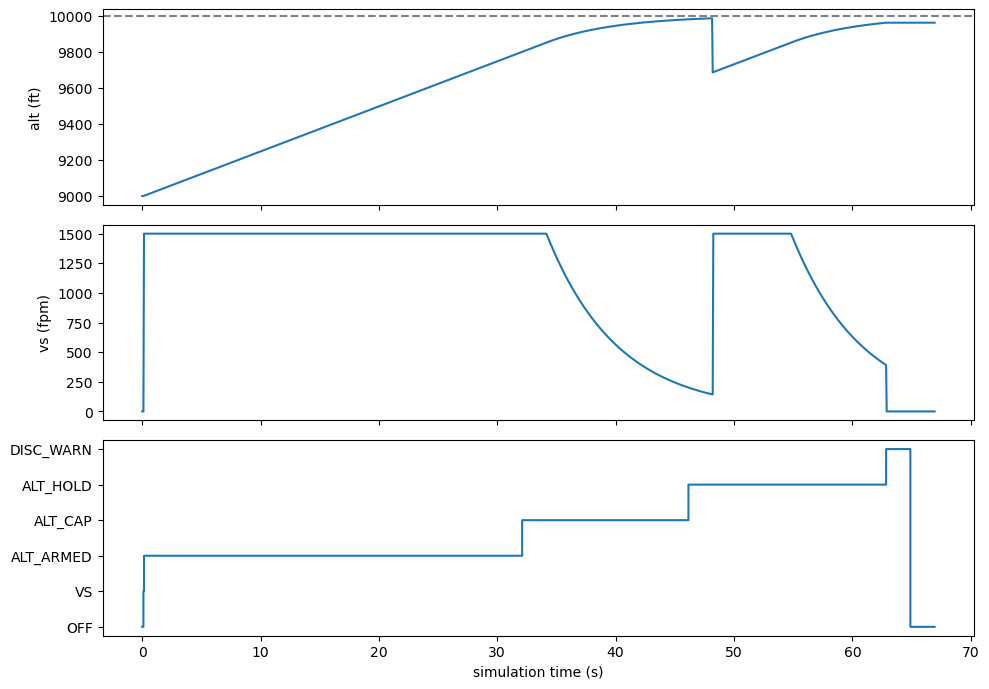

In [9]:
import matplotlib.pyplot as plt
t, alt, vs, mode = zip(*hist)
modes = ["OFF", "VS", "ALT_ARMED", "ALT_CAP", "ALT_HOLD", "DISC_WARN"]
fig, ax = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
ax[0].plot(t, alt); ax[0].axhline(10000, ls="--", c="grey"); ax[0].set_ylabel("alt (ft)")
ax[1].plot(t, vs); ax[1].set_ylabel("vs (fpm)")
ax[2].step(t, [modes.index(m) for m in mode], where="post")
ax[2].set_yticks(range(len(modes)), modes); ax[2].set_xlabel("simulation time (s)")
plt.tight_layout(); plt.show()

## State changes in the trace

In [10]:
for line in trace.lines():
    if '"' in line:                          # state change lines carry the transition title
        print(line)

tick=000003 t=100.000 | AP | ENG OFF->VS "Engage" | ap_disc_cond=False, ap_engage_ok=True, ap_engage_pb=True
tick=000004 t=150.000 | AP | ARM VS->ALT_ARMED "Arm ALT" | alt_arm_pb=True, at_sel_alt=False
tick=000643 t=32100.000 | AP | CAP ALT_ARMED->ALT_CAP "Capture" | in_capture_zone=True
tick=000924 t=46150.000 | AP | HOLD ALT_CAP->ALT_HOLD "Hold" | at_sel_alt=True
tick=001258 t=62850.000 | AP | DISC ALT_HOLD->DISC_WARN "Disconnect" | ap_disc_cond=True, ap_engaged=True
tick=001299 t=64900.000 | AP | ACK DISC_WARN->OFF "Acknowledge" | warn_ack_pb=True
